<a href="https://colab.research.google.com/github/Aoiizu/PCVK2026/blob/main/JS-09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 9 - Morphology


## 1. Mount Google Drive

In [18]:
from google.colab import drive
drive.mount('/content/drive')
IMG = '/content/drive/MyDrive/Images/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Import Libraries and Helpers

In [19]:
import os
import cv2
import numpy as np
from matplotlib import pyplot as plt
from skimage import data, filters, io, color, morphology
from skimage import img_as_float
from skimage.morphology import skeletonize

def show(images, titles, cmap='gray', size=(12, 4)):
    plt.figure(figsize=size)
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(1, len(images), i)
        plt.imshow(im, cmap=cmap)
        plt.title(t)
        plt.xticks([]), plt.yticks([])
    plt.show()

def load_gray(name, fallback):
    path = IMG + name
    if os.path.exists(path):
        return cv2.imread(path, 0)
    print(f'{name} not found in {IMG}, using a substitute image')
    return fallback()

def binarize(gray, t=127):
    return cv2.threshold(gray, t, 255, cv2.THRESH_BINARY)[1]

def window(padded, dy, dx, h, w):
    return padded[dy:dy + h, dx:dx + w]

def dilasi_citra(F, SE):
    h, w = F.shape
    ph, pw = SE.shape[0] // 2, SE.shape[1] // 2
    padded = np.pad(F, ((ph, ph), (pw, pw)), constant_values=0)
    out = np.zeros_like(F)
    for dy, dx in zip(*np.nonzero(SE)):
        out = np.maximum(out, window(padded, dy, dx, h, w))
    return out

def erosi_citra(F, SE):
    h, w = F.shape
    ph, pw = SE.shape[0] // 2, SE.shape[1] // 2
    padded = np.pad(F, ((ph, ph), (pw, pw)), constant_values=0)
    out = np.full_like(F, 255)
    for dy, dx in zip(*np.nonzero(SE)):
        out = np.minimum(out, window(padded, dy, dx, h, w))
    return out

def cross(k):
    return cv2.getStructuringElement(cv2.MORPH_CROSS, (k, k))

def square(k):
    return np.ones((k, k), dtype=np.uint8)

def circle(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

def rect(w, h):
    return cv2.getStructuringElement(cv2.MORPH_RECT, (w, h))

def vline(k):
    return cv2.getStructuringElement(cv2.MORPH_RECT, (1, k))

plate = load_gray('platenumber.jpg', lambda: None)
print(plate.shape)

(1478, 2939)


## 3. Dilation without Library - Cross 3 x 3 SED

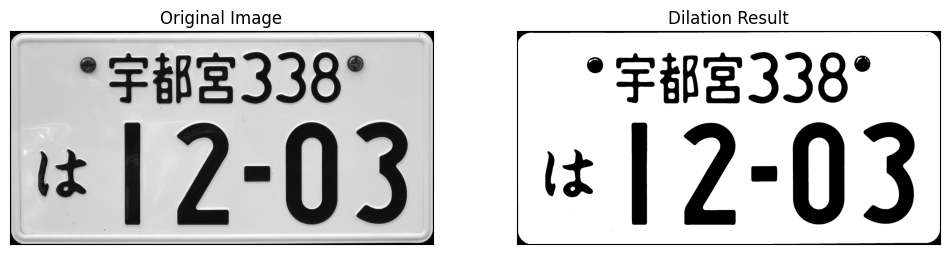

In [20]:
thresh = binarize(plate, 125)
imgD = dilasi_citra(thresh, cross(3))
show([plate, imgD], ['Original Image', 'Dilation Result'])

## 4. Dilation with OpenCV Library - Cross 3 x 3 SED

[[0 1 0]
 [1 1 1]
 [0 1 0]]


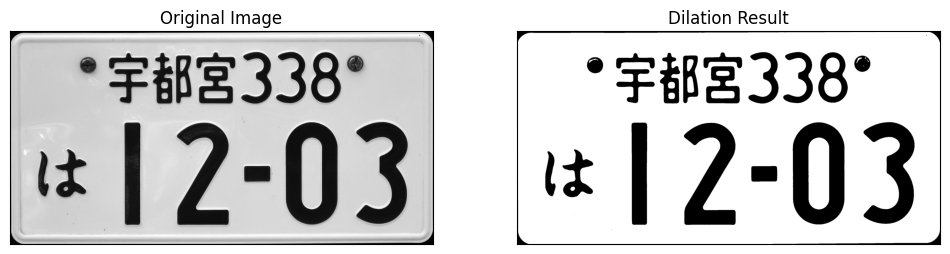

In [21]:
thresh = binarize(plate, 127)
dilasi = cv2.dilate(thresh, cross(3), iterations=1)
print(cross(3))
show([plate, dilasi], ['Original Image', 'Dilation Result'])

## 5. Erosion without Library - Square 5 x 5 SE

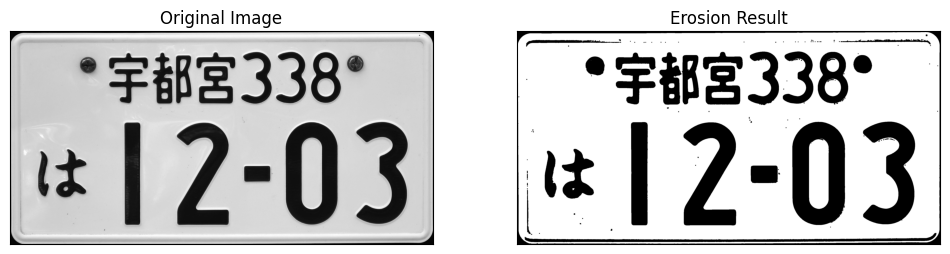

In [22]:
thresh1 = binarize(plate, 175)
imgE = erosi_citra(thresh1, square(5))
show([plate, imgE], ['Original Image', 'Erosion Result'])

## 6. Erosion with OpenCV Library - Square 5 x 5 SE

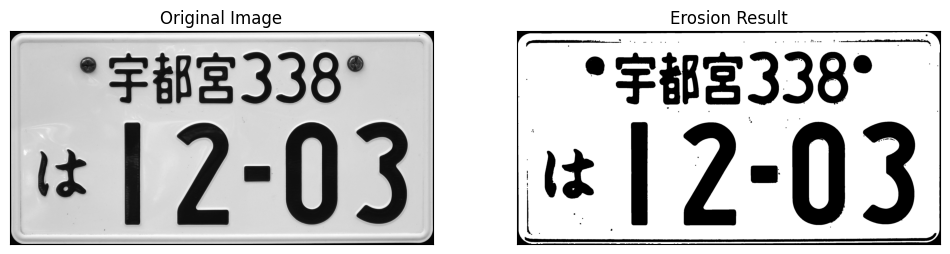

In [23]:
thresh1 = binarize(plate, 175)
erosion = cv2.erode(thresh1, square(5), iterations=1)
show([plate, erosion], ['Original Image', 'Erosion Result'])

## 7. Opening - Square 3 x 3 SE

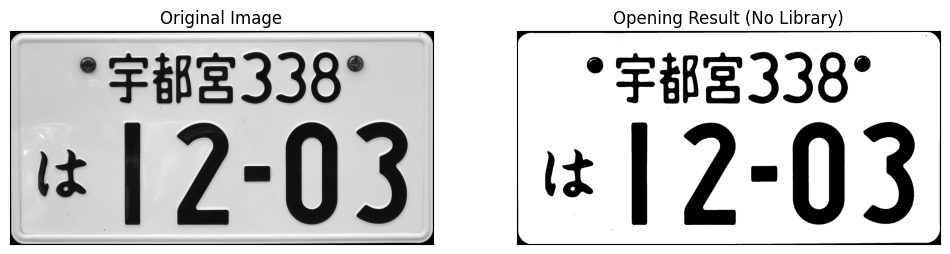

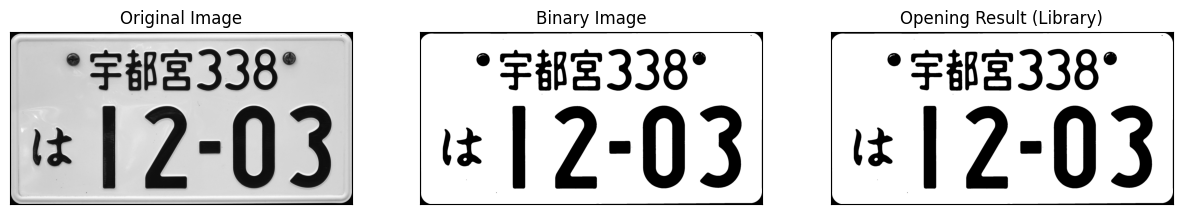

In [24]:
thresh = binarize(plate, 127)

imgO = dilasi_citra(erosi_citra(thresh, square(3)), square(3))
show([plate, imgO], ['Original Image', 'Opening Result (No Library)'])

openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, square(3))
show([plate, thresh, openn], ['Original Image', 'Binary Image', 'Opening Result (Library)'], size=(15, 4))

## 8. Closing - Square 3 x 3 SE

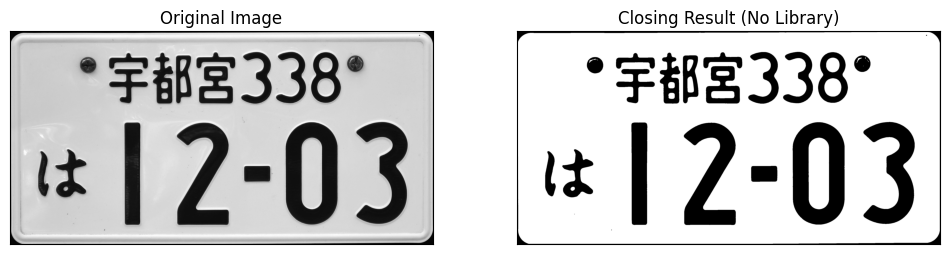

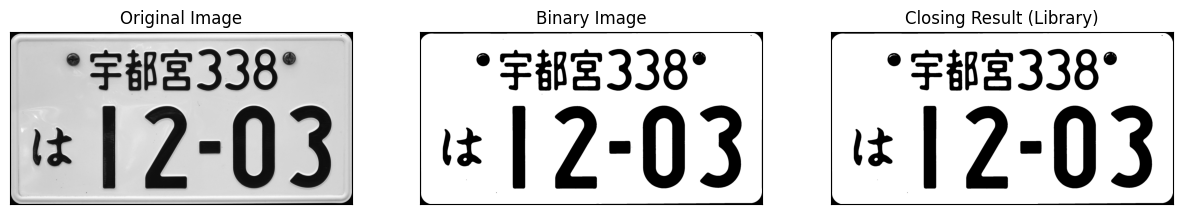

In [25]:
thresh = binarize(plate, 127)

imgC = erosi_citra(dilasi_citra(thresh, square(3)), square(3))
show([plate, imgC], ['Original Image', 'Closing Result (No Library)'])

closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, square(3))
show([plate, thresh, closs], ['Original Image', 'Binary Image', 'Closing Result (Library)'], size=(15, 4))

## 9. Dilation - Cross 3 x 3 and 5 x 5 SED

SED = Cross 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]


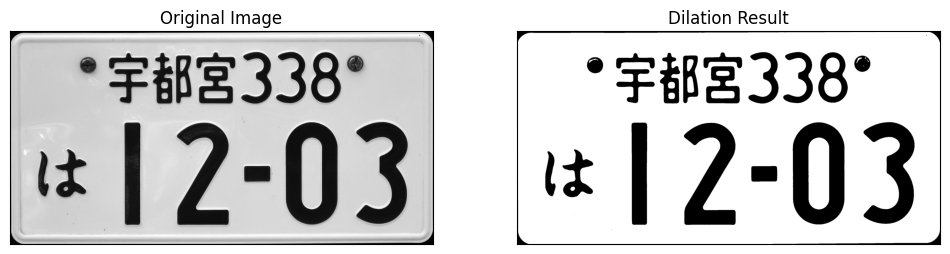

SED = Cross 5
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


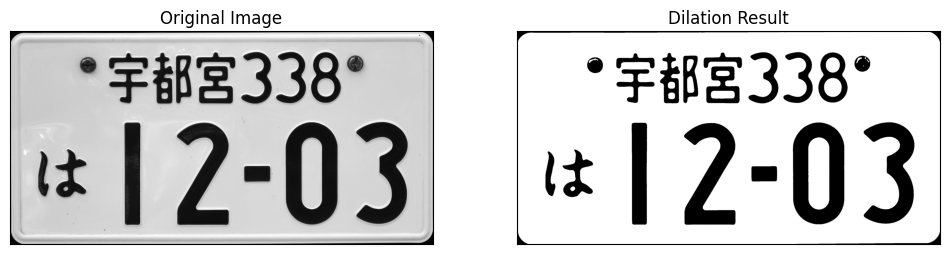

In [26]:
thresh = binarize(plate, 127)
for k in (3, 5):
    print(f'SED = Cross {k}')
    print(cross(k))
    show([plate, dilasi_citra(thresh, cross(k))], ['Original Image', 'Dilation Result'])

## 10. Dilation - Circular 3 x 3 and 5 x 5 SED

SED = Circle 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]


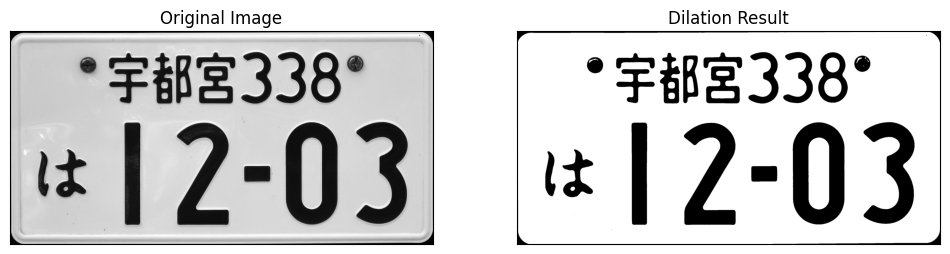

SED = Circle 5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


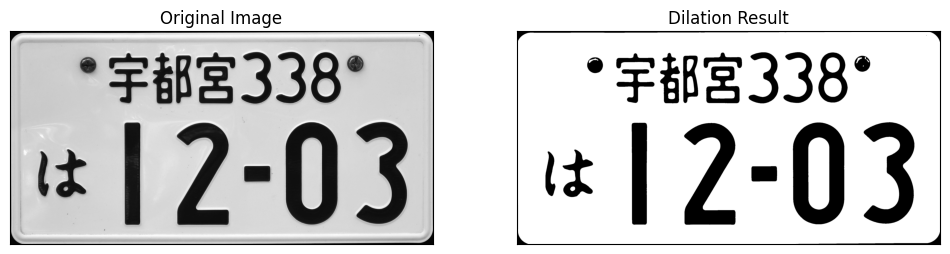

In [27]:
thresh = binarize(plate, 127)
for k in (3, 5):
    print(f'SED = Circle {k}')
    print(circle(k))
    show([plate, dilasi_citra(thresh, circle(k))], ['Original Image', 'Dilation Result'])

## 11. Erosion - Rectangle 3 x 5 and 5 x 7 SE

SE = Rectangle 3x5


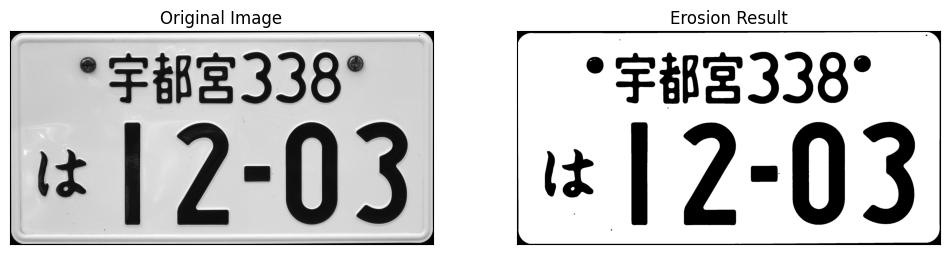

SE = Rectangle 5x7


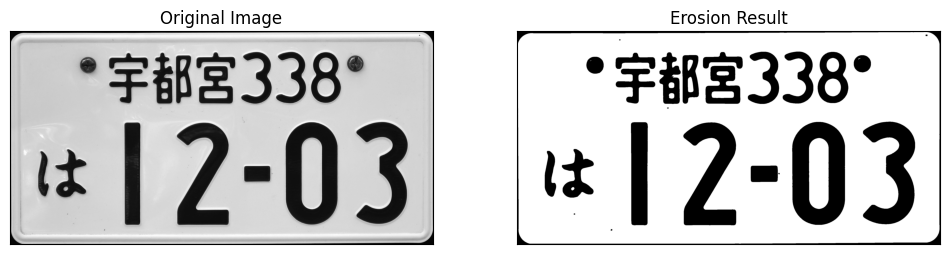

In [28]:
thresh = binarize(plate, 127)
for w, h in ((5, 3), (7, 5)):
    print(f'SE = Rectangle {h}x{w}')
    show([plate, erosi_citra(thresh, rect(w, h))], ['Original Image', 'Erosion Result'])

## 12. Erosion - Vertical Line 3 and 5 SE (image j.png)

j.png not found in /content/drive/MyDrive/Images/, using a substitute image
SE = Vertical Line 3


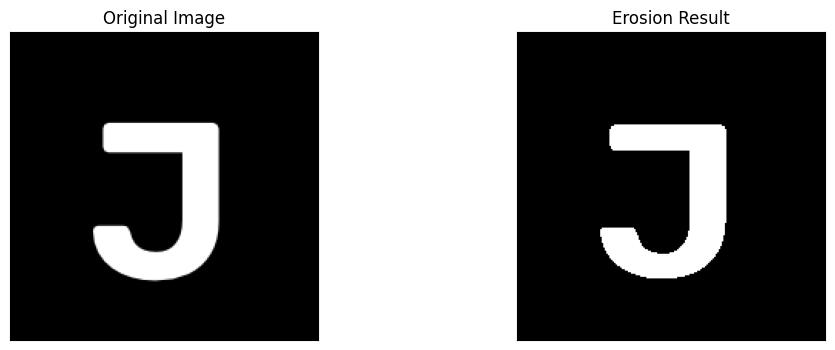

SE = Vertical Line 5


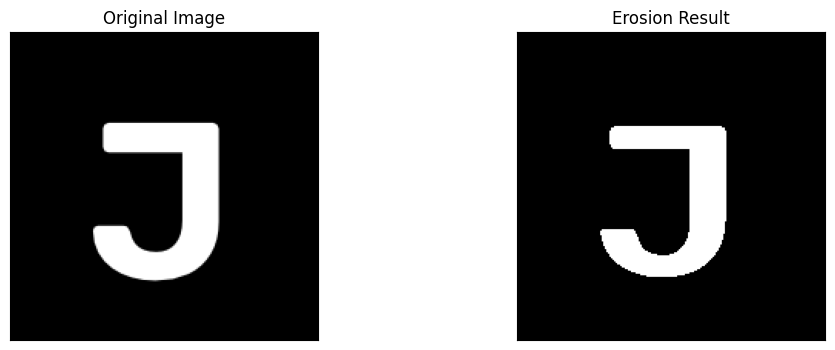

In [29]:
def make_j():
    canvas = np.zeros((200, 200), dtype=np.uint8)
    cv2.putText(canvas, 'J', (50, 160), cv2.FONT_HERSHEY_SIMPLEX, 5, 255, 12)
    return canvas

j_img = load_gray('j.png', make_j)
j_bin = binarize(j_img, 127)
for k in (3, 5):
    print(f'SE = Vertical Line {k}')
    show([j_img, erosi_citra(j_bin, vline(k))], ['Original Image', 'Erosion Result'])

## 13. Top Hat

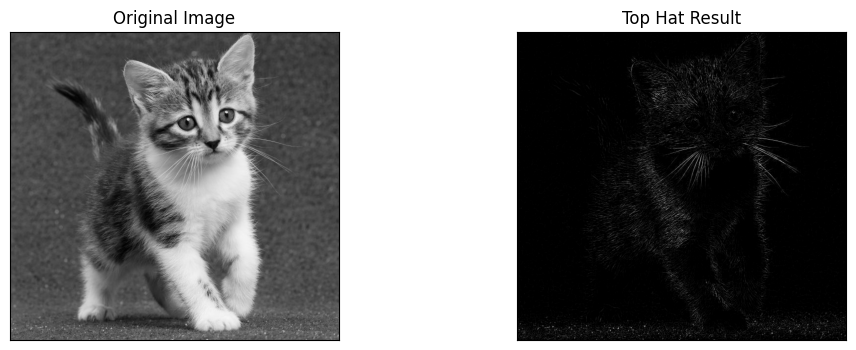

In [30]:
def make_kitten():
    return cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2GRAY)

kitten = load_gray('kitten01.jpg', make_kitten)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
tophat_img = cv2.morphologyEx(kitten, cv2.MORPH_TOPHAT, kernel)
show([kitten, tophat_img], ['Original Image', 'Top Hat Result'])

## 14. Black Hat

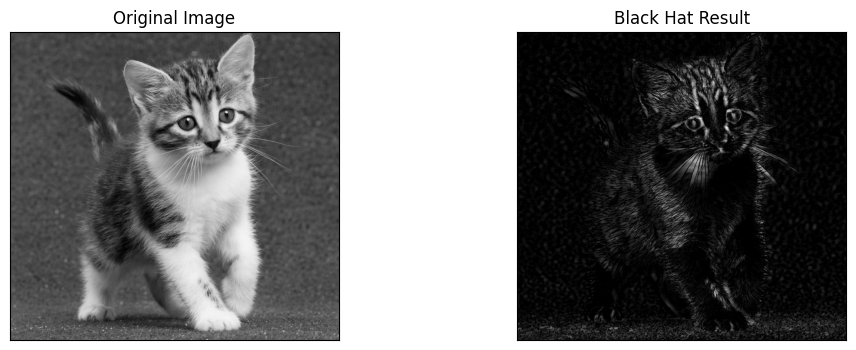

In [31]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(kitten, cv2.MORPH_BLACKHAT, kernel)
show([kitten, blackhat], ['Original Image', 'Black Hat Result'])

## 15. Skeleton

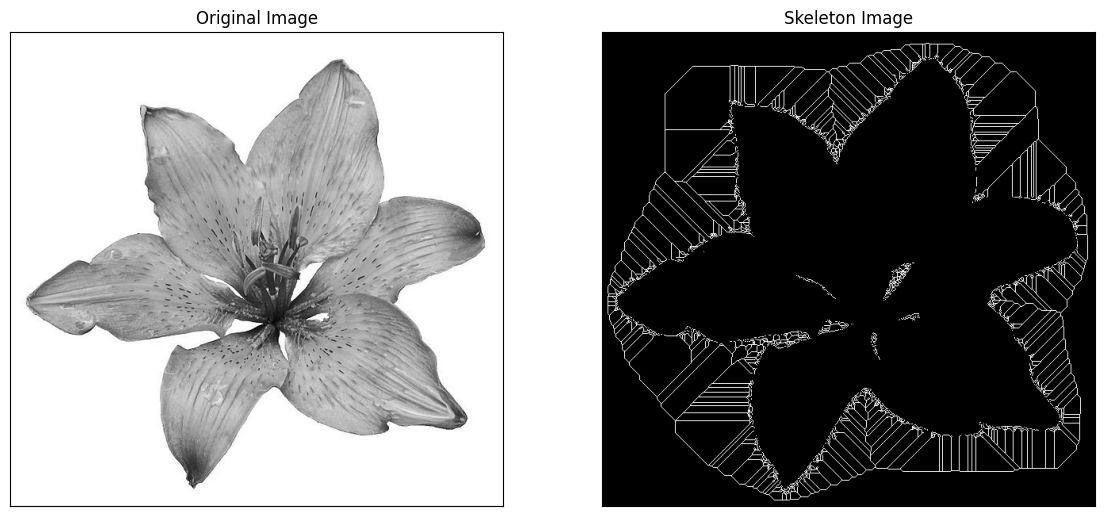

In [32]:
lily = load_gray('lily.jpg', lambda: data.coins())
binary = lily > filters.threshold_triangle(lily)
skeleton = skeletonize(binary)
show([lily, skeleton], ['Original Image', 'Skeleton Image'], size=(14, 7))

## 16. Skeleton Inverse

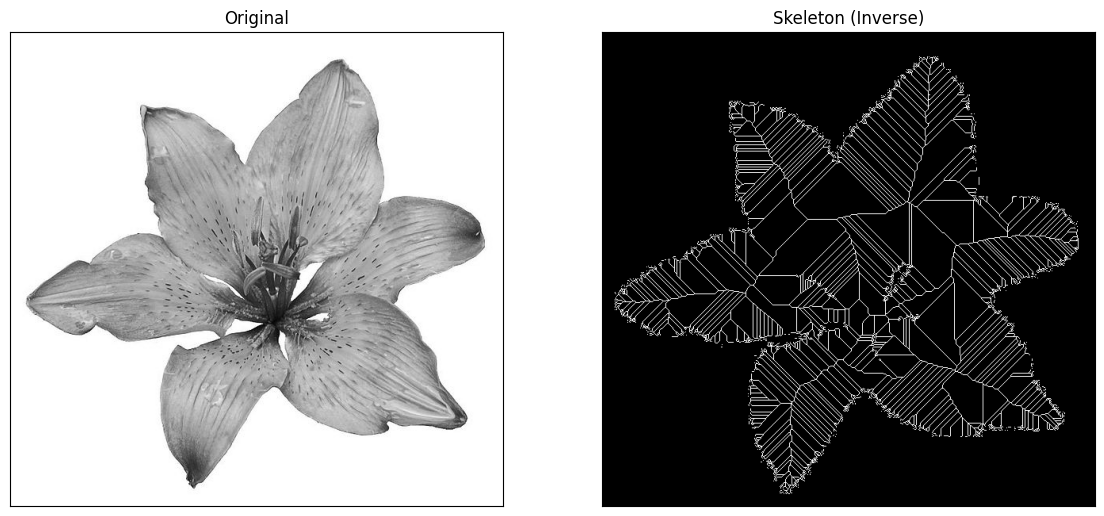

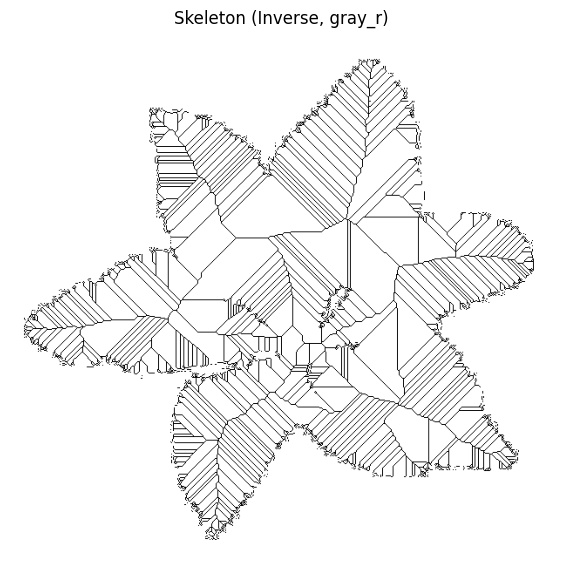

In [33]:
binary_inv = lily < filters.threshold_triangle(lily)
skeleton_inv = skeletonize(binary_inv)
show([lily, skeleton_inv], ['Original', 'Skeleton (Inverse)'], size=(14, 7))
plt.figure(figsize=(7, 7))
plt.imshow(skeleton_inv, cmap='gray_r')
plt.title('Skeleton (Inverse, gray_r)')
plt.axis('off')
plt.show()

## 17. Thickening

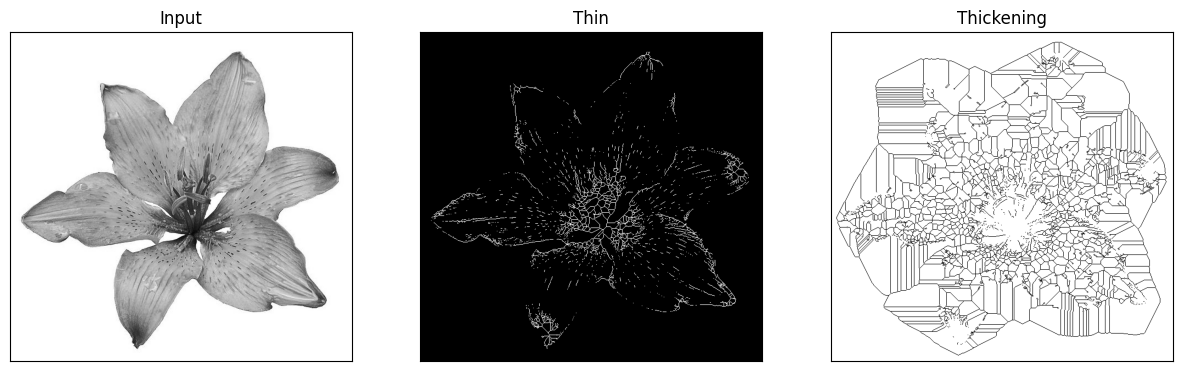

In [34]:
image = img_as_float(lily)
image_binary = image < 0.5
out_thin = morphology.thin(image_binary)
out_thick = ~morphology.thin(~image_binary)
show([image, out_thin, out_thick], ['Input', 'Thin', 'Thickening'], size=(15, 5))